# Approach 3: semantic ticket embeddings + logistic regression

Executed experiment using the final preparation package. **Target:** any recorded escalation, regardless of manager approval. **Inputs:** prepared `model_text` only. No incident similarity or outcome fields are predictors.

The frozen `sentence-transformers/all-MiniLM-L6-v2` encoder produces 384-dimensional, normalized embeddings. Logistic regression learns the escalation classifier. Encoder documentation: https://huggingface.co/sentence-transformers/all-MiniLM-L6-v2

**Evaluation policy fixed before test evaluation:** choose regularization C by validation average precision; select the alert threshold by validation escalation F1 (ties favor precision). Report both this threshold and 0.5, alongside always-alert and always-negative benchmarks. Never tune on test results.

**Limitations:** synthetic data; retrospective outcome labels; no verified initial snapshots; repeated text templates. This is a prototype evaluation, not evidence of live early-warning accuracy. The preparation report explains why strict historical validation was unusable. Test unseen-text subsets are a secondary diagnostic, not an independent holdout.

**Latest evaluation:** the final section runs nested five-fold grouped cross-validation, comparing text-only and structured-feature models. All earlier experiments are retained.

**Latest addition:** see the final structured-feature experiment and summary for text + category + subcategory + assumed initial priority. Earlier sections retain text-only experiments. The structured model is saved separately.

**Updated notebook:** the final follow-up section reduces false positives using a validation-selected threshold. It supersedes the original prediction threshold. Original results remain for comparison. Read the final before/after results before interpreting performance.

In [1]:
from pathlib import Path
import json, hashlib, platform, importlib.metadata, warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import joblib, torch
from sentence_transformers import SentenceTransformer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (accuracy_score, balanced_accuracy_score, precision_score,
    recall_score, f1_score, average_precision_score, roc_auc_score, brier_score_loss,
    confusion_matrix, ConfusionMatrixDisplay, precision_recall_curve, roc_curve,
    classification_report)
from IPython.display import display
BASE = Path.cwd()
if not (BASE / 'data').exists():
    raise RuntimeError('Run this notebook with its containing model_approach3 folder as the working directory.')
RESULTS = BASE / 'results'; RESULTS.mkdir(exist_ok=True)
SEED = 42
np.random.seed(SEED); torch.manual_seed(SEED); torch.set_num_threads(2)
MODEL_ID = 'sentence-transformers/all-MiniLM-L6-v2'


## Load and validate the prepared partitions

In [2]:
frames = {s: pd.read_csv(BASE / 'data' / f'{s}.csv') for s in ['train','validation','test']}
for s,d in frames.items():
    assert d.ticket_id.is_unique
    assert d.model_text.notna().all() and d.model_text.str.strip().ne('').all()
    assert set(d.escalation_label.unique()) == {0,1}
for a,b in [('train','validation'),('train','test'),('validation','test')]:
    assert set(frames[a].ticket_id).isdisjoint(frames[b].ticket_id)
    assert set(frames[a].event_group_id).isdisjoint(frames[b].event_group_id)
    assert pd.to_datetime(frames[a].created_at).max() < pd.to_datetime(frames[b].created_at).min()
summary = pd.DataFrame([{'split':s,'tickets':len(d),'escalated':int(d.escalation_label.sum()),
    'not_escalated':int((d.escalation_label==0).sum()),'escalation_rate':d.escalation_label.mean()}
    for s,d in frames.items()])
display(summary)
summary.to_csv(RESULTS/'split_summary.csv',index=False)


,split,tickets,escalated,not_escalated,escalation_rate
0,train,1797,1544,253,0.859210
1,validation,341,289,52,0.847507
2,test,458,386,72,0.842795


## Encode descriptions using the frozen pretrained model
Embeddings depend only on text. There is no fitting on validation/test data. Identical text is encoded once to save time. Inputs longer than 256 word pieces are truncated; the count is reported.

In [3]:
encoder_path = BASE / 'encoder'
encoder = SentenceTransformer(str(encoder_path) if encoder_path.exists() else MODEL_ID, device='cpu')
encoder.max_seq_length = 256
if not encoder_path.exists(): encoder.save(str(encoder_path))
unique_texts = list(dict.fromkeys(t for d in frames.values() for t in d.model_text))
lengths = [len(encoder.tokenizer(t, truncation=False)['input_ids']) for t in unique_texts]
embedding_array = encoder.encode(unique_texts, batch_size=32, normalize_embeddings=True, show_progress_bar=False)
assert embedding_array.shape == (len(unique_texts),384) and np.isfinite(embedding_array).all()
lookup = {t:v for t,v in zip(unique_texts,embedding_array)}
X = {s:np.stack([lookup[t] for t in d.model_text]) for s,d in frames.items()}
y = {s:d.escalation_label.to_numpy(dtype=int) for s,d in frames.items()}
np.savez_compressed(RESULTS/'embeddings.npz', **X)
print(f'Unique descriptions: {len(unique_texts)}; embedding dimensions: {embedding_array.shape[1]}')
print(f'Descriptions exceeding 256 tokens: {sum(v>256 for v in lengths)}; maximum tokens: {max(lengths)}')


Loading weights: 100%|##########| 103/103 [00:00<00:00, 4142.18it/s]
Unique descriptions: 1040; embedding dimensions: 384
Descriptions exceeding 256 tokens: 0; maximum tokens: 40


## Train candidates and select using validation only
C controls regularization. No class weighting is applied: the observed training distribution is retained. Average precision selects the ranking model; F1 chooses the operating threshold. An operational recall target can replace this policy in a future experiment, before examining its test set.

In [4]:
candidates=[]; models={}
for C in [0.01,0.1,1.0,10.0,100.0]:
    clf=LogisticRegression(C=C,max_iter=2000,random_state=SEED,solver='lbfgs')
    clf.fit(X['train'],y['train'])
    assert clf.n_iter_.max() < clf.max_iter
    vp=clf.predict_proba(X['validation'])[:,1]
    candidates.append({'C':C,'validation_average_precision':average_precision_score(y['validation'],vp)})
    models[C]=clf
selection=pd.DataFrame(candidates).sort_values(['validation_average_precision','C'],ascending=[False,True])
best_C=float(selection.iloc[0].C); model=models[best_C]
vp=model.predict_proba(X['validation'])[:,1]
thresholds=np.unique(np.r_[0.0,vp,1.0])
threshold_rows=[]
for t in thresholds:
    pred=(vp>=t).astype(int)
    threshold_rows.append({'threshold':float(t),'f1':f1_score(y['validation'],pred,zero_division=0),
        'precision':precision_score(y['validation'],pred,zero_division=0),
        'recall':recall_score(y['validation'],pred,zero_division=0),'alert_rate':pred.mean()})
threshold_table=pd.DataFrame(threshold_rows)
best=threshold_table.sort_values(['f1','precision','threshold'],ascending=[False,False,False]).iloc[0]
threshold=float(best.threshold)
display(selection); display(best.to_frame('selected validation operating point'))
selection.to_csv(RESULTS/'validation_model_selection.csv',index=False)
threshold_table.to_csv(RESULTS/'validation_thresholds.csv',index=False)
joblib.dump({'classifier':model,'threshold':threshold,'encoder_name':MODEL_ID,
    'normalize_embeddings':True,'max_seq_length':256,'feature':'model_text'},RESULTS/'escalation_model.joblib')


,C,validation_average_precision
2,1.00,0.924196
3,10.00,0.918671
4,100.00,0.917431
1,0.10,0.917147
0,0.01,0.901997


,selected validation operating point
threshold,0.630039
f1,0.917460
precision,0.847507
recall,1.000000
alert_rate,1.000000


## Evaluate the frozen choice on test data
Rows in the confusion matrix are actual labels, columns are predictions. Label 1 means escalated. Average precision and ROC AUC measure ranking; precision/recall/F1/alert rate depend on the threshold. Brier score measures probability error; these probabilities have not been separately calibrated.

In [5]:
def evaluate(name,split,truth,score,cutoff):
    pred=(score>=cutoff).astype(int)
    tn,fp,fn,tp=confusion_matrix(truth,pred,labels=[0,1]).ravel()
    two=len(np.unique(truth))==2
    return {'model':name,'split':split,'n':len(truth),'threshold':cutoff,
        'accuracy':accuracy_score(truth,pred),'balanced_accuracy':balanced_accuracy_score(truth,pred),
        'precision':precision_score(truth,pred,zero_division=0),'recall':recall_score(truth,pred,zero_division=0),
        'f1':f1_score(truth,pred,zero_division=0),'average_precision':average_precision_score(truth,score) if two else np.nan,
        'roc_auc':roc_auc_score(truth,score) if two else np.nan,'brier_score':brier_score_loss(truth,score),
        'alert_rate':pred.mean(),'tn':int(tn),'fp':int(fp),'fn':int(fn),'tp':int(tp)}
scores={s:model.predict_proba(X[s])[:,1] for s in frames}
rows=[]
for s in ['validation','test']:
    rows.append(evaluate('semantic_LR_tuned',s,y[s],scores[s],threshold))
    rows.append(evaluate('semantic_LR_0.5',s,y[s],scores[s],0.5))
    # Both use the training prevalence as their constant ranking/probability score.
    constant=np.full(len(y[s]),y['train'].mean())
    rows.append(evaluate('always_alert',s,y[s],constant,0.0))
    rows.append(evaluate('always_negative',s,y[s],constant,1.0))
    out=frames[s].copy();out['risk_score']=scores[s];out['threshold']=threshold
    out['prediction']=(scores[s]>=threshold).astype(int)
    out['correct']=out.prediction.eq(out.escalation_label)
    out.to_csv(RESULTS/f'{s}_predictions.csv',index=False)
    report=classification_report(y[s],out.prediction,labels=[0,1],target_names=['not_escalated','escalated'],output_dict=True,zero_division=0)
    (RESULTS/f'{s}_classification_report.json').write_text(json.dumps(report,indent=2))
    pd.DataFrame(confusion_matrix(y[s],out.prediction,labels=[0,1]),index=['actual_not_escalated','actual_escalated'],
        columns=['predicted_not_escalated','predicted_escalated']).to_csv(RESULTS/f'{s}_confusion_matrix.csv')
metrics=pd.DataFrame(rows)
display(metrics[metrics.split=='test'].round(4))
print(classification_report(y['test'],scores['test']>=threshold,target_names=['not_escalated','escalated'],zero_division=0))


               precision    recall  f1-score   support

not_escalated       1.00      0.01      0.03        72
    escalated       0.84      1.00      0.92       386

     accuracy                           0.84       458
    macro avg       0.92      0.51      0.47       458
 weighted avg       0.87      0.84      0.78       458



,model,split,n,threshold,accuracy,balanced_accuracy,precision,recall,f1,average_precision,roc_auc,brier_score,alert_rate,tn,fp,fn,tp
4,semantic_LR_tuned,test,458,0.63,0.8450,0.5069,0.8446,1.0,0.9158,0.9065,0.6508,0.1294,0.9978,1,71,0,386
5,semantic_LR_0.5,test,458,0.50,0.8428,0.5000,0.8428,1.0,0.9147,0.9065,0.6508,0.1294,1.0000,0,72,0,386
6,always_alert,test,458,0.00,0.8428,0.5000,0.8428,1.0,0.9147,0.8428,0.5000,0.1328,1.0000,0,72,0,386
7,always_negative,test,458,1.00,0.1572,0.5000,0.0000,0.0,0.0000,0.8428,0.5000,0.1328,0.0000,72,0,386,0


## Secondary evaluation: descriptions not previously seen verbatim
Validation excludes text seen in training. Test excludes text seen in training or validation. The same selected model and threshold are used, with no further tuning. Similar paraphrases may still remain.

In [6]:
seen=set(frames['train'].model_text)
for s in ['validation','test']:
    mask=~frames[s].model_text.isin(seen).to_numpy()
    if mask.any():
        rows.append(evaluate('semantic_LR_tuned',s+'_unseen_text',y[s][mask],scores[s][mask],threshold))
    print(s, 'previously seen exact text:',int((~mask).sum()),'unseen:',int(mask.sum()))
    seen.update(frames[s].model_text)
metrics=pd.DataFrame(rows)
metrics.to_csv(RESULTS/'evaluation_metrics.csv',index=False)
display(metrics[metrics.split.str.contains('unseen')].round(4))


validation previously seen exact text: 243 unseen: 98
test previously seen exact text: 361 unseen: 97


,model,split,n,threshold,accuracy,balanced_accuracy,precision,recall,f1,average_precision,roc_auc,brier_score,alert_rate,tn,fp,fn,tp
8,semantic_LR_tuned,validation_unseen_text,98,0.63,0.8673,0.5000,0.8673,1.0,0.9290,0.9568,0.7538,0.1099,1.0000,0,13,0,85
9,semantic_LR_tuned,test_unseen_text,97,0.63,0.8557,0.5333,0.8542,1.0,0.9213,0.9013,0.6317,0.1281,0.9897,1,14,0,82


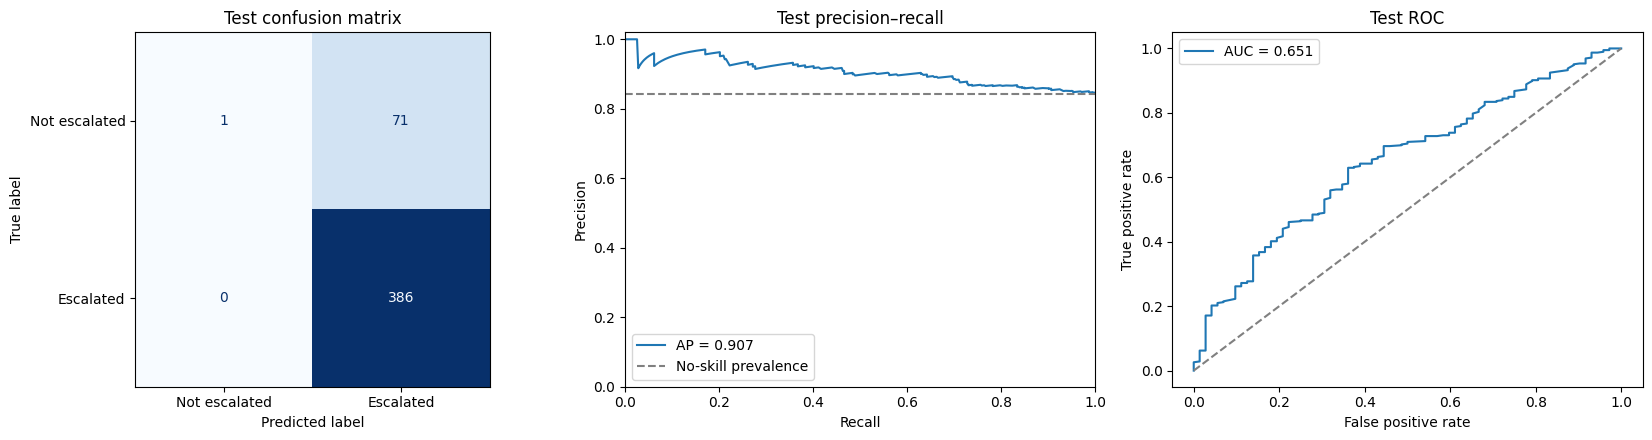

In [7]:
fig,axes=plt.subplots(1,3,figsize=(17,4.5))
ConfusionMatrixDisplay.from_predictions(y['test'],scores['test']>=threshold,
    display_labels=['Not escalated','Escalated'],cmap='Blues',colorbar=False,ax=axes[0])
axes[0].set_title('Test confusion matrix')
p,r,_=precision_recall_curve(y['test'],scores['test'])
axes[1].plot(r,p,label=f"AP = {average_precision_score(y['test'],scores['test']):.3f}")
axes[1].axhline(y['test'].mean(),ls='--',color='grey',label='No-skill prevalence')
axes[1].set(xlabel='Recall',ylabel='Precision',title='Test precision–recall',xlim=(0,1),ylim=(0,1.02));axes[1].legend()
fpr,tpr,_=roc_curve(y['test'],scores['test'])
axes[2].plot(fpr,tpr,label=f"AUC = {roc_auc_score(y['test'],scores['test']):.3f}")
axes[2].plot([0,1],[0,1],'--',color='grey');axes[2].set(xlabel='False positive rate',ylabel='True positive rate',title='Test ROC');axes[2].legend()
fig.tight_layout();fig.savefig(RESULTS/'evaluation_charts.png',dpi=160);plt.show()


## Reproducibility checks and saved artifacts

In [8]:
loaded=joblib.load(RESULTS/'escalation_model.joblib')
assert np.allclose(loaded['classifier'].predict_proba(X['test'])[:,1],scores['test'])
assert loaded['threshold']==threshold
# The model only consumes model_text; outcome fields cannot enter the embedding matrix.
assert model.n_features_in_==384
saved=pd.read_csv(RESULTS/'test_predictions.csv')
assert np.array_equal(saved.prediction,(saved.risk_score>=threshold).astype(int))
assert len(saved)==len(frames['test'])
versions={k:importlib.metadata.version(k) for k in ['sentence-transformers','transformers','torch','scikit-learn','numpy','pandas','matplotlib','joblib','nbformat','nbclient','ipykernel']}
manifest={'encoder':MODEL_ID,'encoder_commit':getattr(encoder[0].auto_model.config,'_commit_hash',None),
    'seed':SEED,'selected_C':best_C,'threshold':threshold,'selection_metric':'validation average precision',
    'threshold_metric':'validation F1, then precision','versions':versions,'python':platform.python_version(),
    'data_sha256':{s:hashlib.sha256((BASE/'data'/f'{s}.csv').read_bytes()).hexdigest() for s in frames},
    'truncated_unique_texts':sum(v>256 for v in lengths),'encoder_frozen':True,
    'limitations':['synthetic data','retrospective labels','initial snapshots unverified','repeated text templates','uncalibrated probabilities']}
(RESULTS/'run_manifest.json').write_text(json.dumps(manifest,indent=2))
print('Passed: split integrity, group separation, text validation, embedding dimensions, convergence, saved-model reproduction, saved predictions.')
print('Results saved to:',RESULTS)


Passed: split integrity, group separation, text validation, embedding dimensions, convergence, saved-model reproduction, saved predictions.
Results saved to: /workspace/scratch/ec4ca456f2d2/outputs/semantic_escalation/results


## Interpretation
Use the printed results to compare the selected model with always alerting. A high F1 alone is insufficient when escalations dominate the sample. Inspect non-escalation recall, false positives, and alert rate. The unseen-text subset exposes exact-template overlap but is small. Real deployment needs representative real tickets, verified initial content, and outcomes observed over a sufficient period.

To score future tickets, apply the same cleaning from `prepare_data.py`, encode `model_text` with the bundled frozen encoder and normalized embeddings, then call the saved classifier’s `predict_proba`. Flag when the score is at least the saved threshold. Do not interpret this synthetic-data score as a validated real-world risk probability.

# Approach 3 — completed model evaluation

## What was trained
Frozen sentence-transformers/all-MiniLM-L6-v2 (384-dimensional normalized embeddings) + logistic regression. Only cleaned model_text is used. No incident similarity, category, priority, team or outcome fields are inputs. All raised escalations count regardless of approval.

Training: 1,797 tickets (1,544 positive, 253 negative). Validation: 341 (289 positive, 52 negative). Test: 458 (386 positive, 72 negative). Unique descriptions across these partitions: 1,040. No descriptions exceeded the 256-token encoder limit.

Selected C=1.0 by validation average precision (0.924196), from [0.01, 0.1, 1, 10, 100]. Selected alert threshold=0.6300394366039118 by validation positive-class F1, with ties favoring precision. Model fitting used training only. Test was evaluated after model and threshold selection; no refit or test-driven tuning was performed.

## Test metrics
| Metric | Semantic model, selected threshold | Always alert |
|---|---:|---:|
| Accuracy | 84.50% | 84.28% |
| Balanced accuracy | 50.69% | 50.00% |
| Precision | 84.46% | 84.28% |
| Recall | 100.00% | 100.00% |
| F1 | 91.58% | 91.47% |
| Average precision | 90.65% | 84.28% |
| ROC AUC | 0.6508 | 0.5000 |
| Alert rate | 99.78% | 100.00% |
| Brier score (lower is better) | 0.1294 | 0.1328 |

The dummy ranking/probability score is the constant TRAINING prevalence; its alert threshold produces always-alert or always-negative decisions. Average precision of constant scores equals test prevalence.

## Test confusion matrix
Rows = actual, columns = predicted.

| | Predicted not escalated | Predicted escalated |
|---|---:|---:|
| Actually not escalated | 1 | 71 |
| Actually escalated | 0 | 386 |

## Interpretation
The model flags 457 of 458 tickets. It catches every test escalation but filters out only one non-escalation. The high positive-class F1 is largely explained by the high escalation prevalence. The selected threshold maximized validation F1 by alerting on ALL validation tickets; this policy offers almost no reduction in review workload. At threshold 0.5 the model alerts on every test ticket.

Ranking has some signal: average precision exceeds the no-skill prevalence and ROC AUC is 0.651. This does not make the current operating point useful for selective alerts. Before a future evaluation, specify an acceptable alert budget or required recall and select a threshold on validation accordingly. Do not tune against the current test results.

On 97 test descriptions not seen verbatim in training or validation: precision 85.42%, recall 100%, F1 92.13%, average precision 90.13%, ROC AUC 0.6317, alert rate 98.97%. This subset contains 82 escalations and only 15 negatives; uncertainty is substantial and similar paraphrases may remain.

## Limitations
- Synthetic records cannot establish real-world predictive performance.
- Preparation uses retrospective labels known by the final observation cutoff, rather than a deployable historical training cutoff. Strict temporal validation in the source package was unusable.
- Initial snapshots were not verified. Removing obvious later notes does not prove remaining text was available at arrival.
- 361 of 458 test descriptions repeat earlier text exactly. The unseen-text diagnostic is smaller and not an independent test sample.
- Scores are not separately calibrated or validated as real-world risk probabilities.
- No statistical confidence interval or claim of significant improvement is made.
- The encoder was frozen; only the logistic regression classifier was trained.

## Delivered files
Approach_3_Escalation.ipynb is executed, with tables and charts. results/ includes metrics, validation selection, thresholds, confusion matrices, classification reports, predictions, embeddings, saved classifier, charts and run manifest. encoder/ bundles the pretrained model so reruns do not require downloading weights. data/ contains exact copies of the preparation escalation partitions. predict.py scores already-cleaned model_text. See README.md for VS Code instructions.

Checks passed: split IDs and groups disjoint, chronological order, valid text and binary labels, finite 384-dimensional embeddings, classifier convergence, saved classifier reproduces scores, saved predictions match the selected threshold. All original preparation ZIP members were retained unchanged in the updated package.


# Follow-up: reduce false positives while preserving escalation recall

The original experiment above is retained for comparison. **This section supersedes the original alert threshold for future predictions.** We keep the frozen encoder and trained classifier unchanged and change the operating threshold.

Before evaluating this follow-up, set a provisional requirement of **at least 90% escalation recall on validation**. Among feasible thresholds, minimize validation false positives; break ties by higher recall, then higher threshold. The recall target is a working assumption to confirm with stakeholders. It is not a guarantee on future data.

The test set has already been examined in the original experiment. Follow-up test metrics are descriptive comparisons, not a fresh unbiased holdout evaluation. No test labels are used in the threshold selection below. A new holdout is needed for final confirmation.

In [9]:
# Validation-only threshold optimization; no test results used here.
MIN_RECALL = 0.90
original_threshold = threshold
candidates_fp = []
for t in np.unique(np.r_[0.0, scores['validation'], 1.0]):
    pred = scores['validation'] >= t
    tn, fp, fn, tp = confusion_matrix(y['validation'], pred, labels=[0,1]).ravel()
    candidates_fp.append({'threshold':float(t), 'tn':int(tn), 'fp':int(fp),
        'fn':int(fn), 'tp':int(tp), 'recall':tp/(tp+fn),
        'precision':tp/(tp+fp) if tp+fp else 0.0, 'alert_rate':float(pred.mean())})
fp_table = pd.DataFrame(candidates_fp)
feasible = fp_table[fp_table.recall >= MIN_RECALL]
assert not feasible.empty
chosen = feasible.sort_values(['fp','recall','threshold'], ascending=[True,False,False]).iloc[0]
reduced_fp_threshold = float(chosen.threshold)
assert chosen.recall >= MIN_RECALL
fp_table.to_csv(RESULTS/'false_positive_threshold_candidates.csv', index=False)
display(chosen.to_frame('validation-selected reduced-FP operating point'))
print('Original threshold:',original_threshold,'New threshold:',reduced_fp_threshold)


Original threshold: 0.6300394366039128 New threshold: 0.7134385308602522


,validation-selected reduced-FP operating point
threshold,0.713439
tn,12.000000
fp,40.000000
fn,25.000000
tp,264.000000
recall,0.913495
precision,0.868421
alert_rate,0.891496


In [10]:
# Evaluate the already-selected threshold without further tuning.
comparison=[]
for s in ['validation','test']:
    comparison.append(evaluate('original_F1_threshold',s,y[s],scores[s],original_threshold))
    comparison.append(evaluate('reduced_FP_recall90',s,y[s],scores[s],reduced_fp_threshold))
    output=frames[s].copy()
    output['risk_score']=scores[s]
    output['alert_threshold']=reduced_fp_threshold
    output['prediction']=(scores[s]>=reduced_fp_threshold).astype(int)
    output['original_prediction']=(scores[s]>=original_threshold).astype(int)
    output['correct']=output.prediction.eq(output.escalation_label)
    output.to_csv(RESULTS/f'{s}_predictions_reduced_fp.csv',index=False)
    report=classification_report(y[s],output.prediction,labels=[0,1],
        target_names=['not_escalated','escalated'],output_dict=True,zero_division=0)
    (RESULTS/f'{s}_classification_report_reduced_fp.json').write_text(json.dumps(report,indent=2))
    pd.DataFrame(confusion_matrix(y[s],output.prediction,labels=[0,1]),
        index=['actual_not_escalated','actual_escalated'],
        columns=['predicted_not_escalated','predicted_escalated']).to_csv(RESULTS/f'{s}_confusion_matrix_reduced_fp.csv')
comparison=pd.DataFrame(comparison)
comparison.to_csv(RESULTS/'false_positive_comparison.csv',index=False)
display(comparison.round(4))
print('Updated test classification report:')
print(classification_report(y['test'],scores['test']>=reduced_fp_threshold,
    target_names=['not_escalated','escalated'],zero_division=0))
seen_before_test=set(frames['train'].model_text)|set(frames['validation'].model_text)
unseen=~frames['test'].model_text.isin(seen_before_test).to_numpy()
unseen_result=evaluate('reduced_FP_recall90','test_unseen_text',y['test'][unseen],scores['test'][unseen],reduced_fp_threshold)
display(pd.DataFrame([unseen_result]).round(4))
pd.DataFrame([unseen_result]).to_csv(RESULTS/'unseen_text_reduced_fp.csv',index=False)


Updated test classification report:
               precision    recall  f1-score   support

not_escalated       0.25      0.25      0.25        72
    escalated       0.86      0.86      0.86       386

     accuracy                           0.76       458
    macro avg       0.56      0.56      0.56       458
 weighted avg       0.76      0.76      0.76       458



,model,split,n,threshold,accuracy,balanced_accuracy,precision,recall,f1,average_precision,roc_auc,brier_score,alert_rate,tn,fp,fn,tp
0,original_F1_threshold,validation,341,0.6300,0.8475,0.5000,0.8475,1.0000,0.9175,0.9242,0.7075,0.1217,1.0000,0,52,0,289
1,reduced_FP_recall90,validation,341,0.7134,0.8094,0.5721,0.8684,0.9135,0.8904,0.9242,0.7075,0.1217,0.8915,12,40,25,264
2,original_F1_threshold,test,458,0.6300,0.8450,0.5069,0.8446,1.0000,0.9158,0.9065,0.6508,0.1294,0.9978,1,71,0,386
3,reduced_FP_recall90,test,458,0.7134,0.7642,0.5551,0.8601,0.8601,0.8601,0.9065,0.6508,0.1294,0.8428,18,54,54,332


,model,split,n,threshold,accuracy,balanced_accuracy,precision,recall,f1,average_precision,roc_auc,brier_score,alert_rate,tn,fp,fn,tp
0,reduced_FP_recall90,test_unseen_text,97,0.7134,0.8351,0.5756,0.8667,0.9512,0.907,0.9013,0.6317,0.1281,0.9278,3,12,4,78


Saved updated default threshold; original model retained. Reload and prediction consistency checks passed.
Ranking scores, average precision and ROC AUC do not change when only the threshold changes.


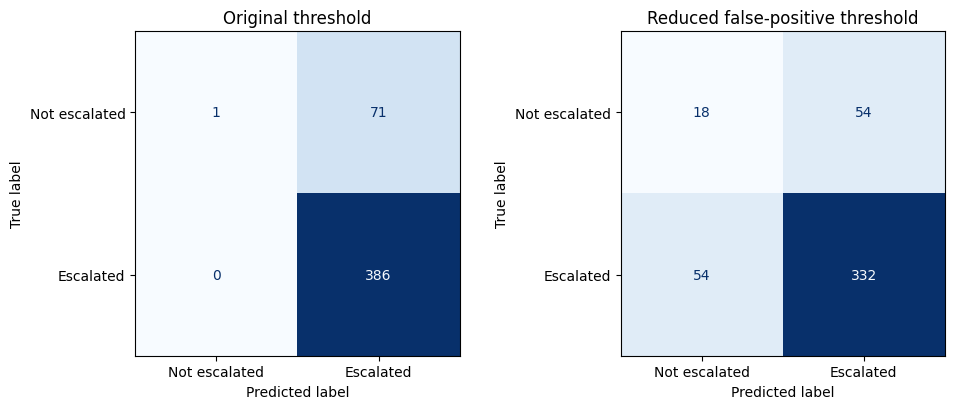

In [11]:
fig,axes=plt.subplots(1,2,figsize=(10,4.2))
for ax,t,title in zip(axes,[original_threshold,reduced_fp_threshold],['Original threshold','Reduced false-positive threshold']):
    ConfusionMatrixDisplay.from_predictions(y['test'],scores['test']>=t,
        display_labels=['Not escalated','Escalated'],ax=ax,cmap='Blues',colorbar=False)
    ax.set_title(title)
fig.tight_layout();fig.savefig(RESULTS/'confusion_matrix_comparison.png',dpi=160);plt.show()

# Preserve the original artifact, then make the new threshold the prediction default.
original_artifact={'classifier':model,'threshold':original_threshold,'encoder_name':MODEL_ID,
    'normalize_embeddings':True,'max_seq_length':256,'feature':'model_text'}
joblib.dump(original_artifact,RESULTS/'escalation_model_original.joblib')
updated_artifact={**original_artifact,'threshold':reduced_fp_threshold,
    'threshold_policy':'minimize validation FP subject to recall >= 0.90',
    'validation_min_recall':MIN_RECALL}
joblib.dump(updated_artifact,RESULTS/'escalation_model.joblib')
restored=joblib.load(RESULTS/'escalation_model.joblib')
assert restored['threshold']==reduced_fp_threshold
assert np.allclose(restored['classifier'].predict_proba(X['test'])[:,1],scores['test'])
pred_saved=pd.read_csv(RESULTS/'test_predictions_reduced_fp.csv')
assert np.array_equal(pred_saved.prediction,(scores['test']>=restored['threshold']).astype(int))
manifest['original_threshold']=original_threshold
manifest['threshold']=reduced_fp_threshold
manifest['threshold_metric']='minimum validation false positives subject to recall >= 0.90; ties prefer recall, then threshold'
manifest['validation_min_recall']=MIN_RECALL
manifest['test_reused_for_followup']=True
manifest['classifier_retrained_in_followup']=False
(RESULTS/'run_manifest.json').write_text(json.dumps(manifest,indent=2))
print('Saved updated default threshold; original model retained. Reload and prediction consistency checks passed.')
print('Ranking scores, average precision and ROC AUC do not change when only the threshold changes.')


# Updated operating threshold — fewer false positives

The notebook now contains a completed follow-up section, **Follow-up: reduce false positives while preserving escalation recall**. Earlier sections retain the original experiment. The saved default model uses the updated threshold.

The encoder and classifier are unchanged. The decision threshold increased from 0.630039 to 0.713439, selected using validation only to minimize false positives while retaining at least 90% validation escalation recall. Ties favor recall, then threshold. This is an operating-point change, not improved text understanding or ranking.

| Test metric | Original | Updated |
|

# Additional experiment: text + category + subcategory + initial priority

**Assumption authorized for this experiment:** the supplied category, subcategory and priority represent the correct initial values. The export has no verified initial snapshots, so results are conditional on that assumption. We do not use assignment group or outcome fields.

Use the same cleaned short-description + description embeddings and the exact same ticket partitions. Fit one-hot encoding on training data only, representing missing values explicitly and allowing unseen categories. Select C by validation average precision, then minimize validation false positives subject to at least 90% recall, exactly as the text-only follow-up. Test outcomes never enter selection. The previously examined test set provides an exploratory comparison, not an independent confirmation.

In [12]:
from sklearn.preprocessing import OneHotEncoder
from scipy.sparse import csr_matrix, hstack
STRUCTURED_FIELDS=['category','subcategory','priority']
metadata=pd.read_csv(BASE/'data/assumed_initial_fields.csv',dtype=str)
assert metadata.ticket_id.is_unique
structured={}
for s,d in frames.items():
    joined=d[['ticket_id']].merge(metadata,on='ticket_id',how='left',validate='one_to_one',indicator=True)
    assert joined['_merge'].eq('both').all()
    assert joined.ticket_id.tolist()==d.ticket_id.tolist()
    structured[s]=joined[STRUCTURED_FIELDS].fillna('__MISSING__').replace('', '__MISSING__')
onehot=OneHotEncoder(handle_unknown='ignore',sparse_output=True,dtype=np.float64)
onehot.fit(structured['train'])
combined_X={s:hstack([csr_matrix(X[s]),onehot.transform(structured[s])],format='csr') for s in frames}
print('Text dimensions:',X['train'].shape[1], 'one-hot dimensions:',len(onehot.get_feature_names_out()),
      'total:',combined_X['train'].shape[1])
for s in frames:
    print(s,'missing field counts:',(structured[s]=='__MISSING__').sum().to_dict())
combined_candidates=[];combined_models={}
for C in [0.01,0.1,1.0,10.0,100.0]:
    clf=LogisticRegression(C=C,max_iter=2000,random_state=SEED,solver='lbfgs')
    clf.fit(combined_X['train'],y['train'])
    assert clf.n_iter_.max()<clf.max_iter
    val_score=clf.predict_proba(combined_X['validation'])[:,1]
    combined_candidates.append({'C':C,'validation_average_precision':average_precision_score(y['validation'],val_score)})
    combined_models[C]=clf
combined_selection=pd.DataFrame(combined_candidates).sort_values(['validation_average_precision','C'],ascending=[False,True])
combined_C=float(combined_selection.iloc[0].C)
combined_model=combined_models[combined_C]
combined_val=combined_model.predict_proba(combined_X['validation'])[:,1]
combined_threshold_rows=[]
for t in np.unique(np.r_[0.,combined_val,1.]):
    pred=combined_val>=t
    tn,fp,fn,tp=confusion_matrix(y['validation'],pred,labels=[0,1]).ravel()
    combined_threshold_rows.append({'threshold':float(t),'fp':int(fp),'fn':int(fn),'tp':int(tp),'tn':int(tn),
        'recall':tp/(tp+fn),'precision':tp/(tp+fp) if tp+fp else 0.})
combined_threshold_table=pd.DataFrame(combined_threshold_rows)
combined_choice=combined_threshold_table[combined_threshold_table.recall>=MIN_RECALL].sort_values(
    ['fp','recall','threshold'],ascending=[True,False,False]).iloc[0]
combined_threshold=float(combined_choice.threshold)
combined_selection.to_csv(RESULTS/'structured_validation_model_selection.csv',index=False)
combined_threshold_table.to_csv(RESULTS/'structured_validation_thresholds.csv',index=False)
display(combined_selection);display(combined_choice.to_frame('selected structured configuration'))


Text dimensions: 384 one-hot dimensions: 55 total: 439
train missing field counts: {'category': 7, 'subcategory': 7, 'priority': 0}
validation missing field counts: {'category': 3, 'subcategory': 3, 'priority': 0}
test missing field counts: {'category': 0, 'subcategory': 0, 'priority': 0}


,C,validation_average_precision
2,1.00,0.948133
1,0.10,0.947527
0,0.01,0.945717
3,10.00,0.941741
4,100.00,0.936765


,selected structured configuration
threshold,0.703194
fp,38.000000
fn,28.000000
tp,261.000000
tn,14.000000
recall,0.903114
precision,0.872910


               precision    recall  f1-score   support

not_escalated       0.30      0.28      0.29        72
    escalated       0.87      0.88      0.87       386

     accuracy                           0.78       458
    macro avg       0.58      0.58      0.58       458
 weighted avg       0.78      0.78      0.78       458



,model,split,n,threshold,accuracy,balanced_accuracy,precision,recall,f1,average_precision,roc_auc,brier_score,alert_rate,tn,fp,fn,tp
0,text_only_recall90,validation,341,0.7134,0.8094,0.5721,0.8684,0.9135,0.8904,0.9242,0.7075,0.1217,0.8915,12,40,25,264
1,text_plus_structured_recall90,validation,341,0.7032,0.8065,0.5862,0.8729,0.9031,0.8878,0.9481,0.7738,0.1134,0.8768,14,38,28,261
2,text_only_recall90,test,458,0.7134,0.7642,0.5551,0.8601,0.8601,0.8601,0.9065,0.6508,0.1294,0.8428,18,54,54,332
3,text_plus_structured_recall90,test,458,0.7032,0.7838,0.5780,0.8670,0.8782,0.8726,0.9288,0.7212,0.1232,0.8537,20,52,47,339


,model,split,n,threshold,accuracy,balanced_accuracy,precision,recall,f1,average_precision,roc_auc,brier_score,alert_rate,tn,fp,fn,tp
0,text_plus_structured_recall90,test_unseen_text,97,0.7032,0.8351,0.5756,0.8667,0.9512,0.907,0.921,0.7154,0.1233,0.9278,3,12,4,78


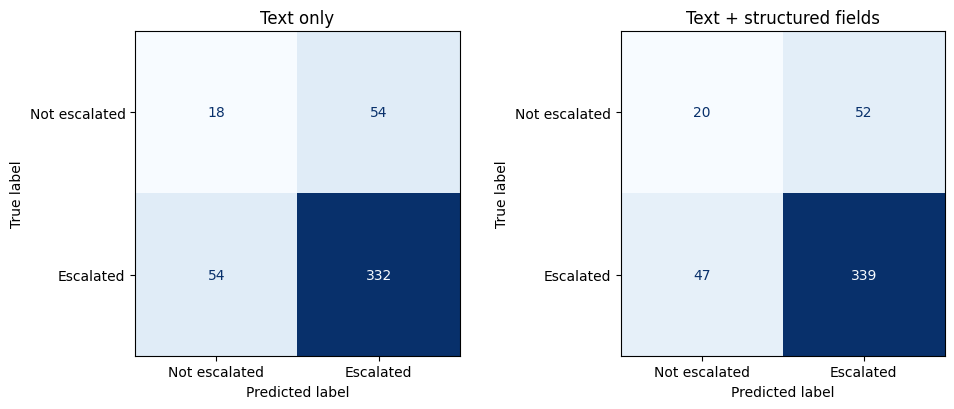

In [13]:
combined_scores={s:combined_model.predict_proba(combined_X[s])[:,1] for s in frames}
structured_comparison=[]
for s in ['validation','test']:
    structured_comparison.append(evaluate('text_only_recall90',s,y[s],scores[s],reduced_fp_threshold))
    structured_comparison.append(evaluate('text_plus_structured_recall90',s,y[s],combined_scores[s],combined_threshold))
    out=frames[s].copy()
    for f in STRUCTURED_FIELDS:out[f]=structured[s][f].to_numpy()
    out['risk_score']=combined_scores[s];out['alert_threshold']=combined_threshold
    out['prediction']=(combined_scores[s]>=combined_threshold).astype(int)
    out['text_only_prediction']=(scores[s]>=reduced_fp_threshold).astype(int)
    out['correct']=out.prediction.eq(out.escalation_label)
    out.to_csv(RESULTS/f'{s}_predictions_structured.csv',index=False)
    cr=classification_report(y[s],out.prediction,labels=[0,1],target_names=['not_escalated','escalated'],output_dict=True,zero_division=0)
    (RESULTS/f'{s}_classification_report_structured.json').write_text(json.dumps(cr,indent=2))
    pd.DataFrame(confusion_matrix(y[s],out.prediction,labels=[0,1]),index=['actual_not_escalated','actual_escalated'],
        columns=['predicted_not_escalated','predicted_escalated']).to_csv(RESULTS/f'{s}_confusion_matrix_structured.csv')
structured_comparison=pd.DataFrame(structured_comparison)
structured_comparison.to_csv(RESULTS/'structured_comparison.csv',index=False)
display(structured_comparison.round(4))
print(classification_report(y['test'],combined_scores['test']>=combined_threshold,target_names=['not_escalated','escalated'],zero_division=0))
structured_unseen=evaluate('text_plus_structured_recall90','test_unseen_text',y['test'][unseen],combined_scores['test'][unseen],combined_threshold)
display(pd.DataFrame([structured_unseen]).round(4))
pd.DataFrame([structured_unseen]).to_csv(RESULTS/'unseen_text_structured.csv',index=False)
fig,axes=plt.subplots(1,2,figsize=(10,4.2))
for ax,sc,t,title in [(axes[0],scores['test'],reduced_fp_threshold,'Text only'),
                      (axes[1],combined_scores['test'],combined_threshold,'Text + structured fields')]:
    ConfusionMatrixDisplay.from_predictions(y['test'],sc>=t,display_labels=['Not escalated','Escalated'],ax=ax,cmap='Blues',colorbar=False)
    ax.set_title(title)
fig.tight_layout();fig.savefig(RESULTS/'structured_confusion_comparison.png',dpi=160);plt.show()


In [14]:
combined_artifact={'classifier':combined_model,'onehot':onehot,'structured_fields':STRUCTURED_FIELDS,
    'threshold':combined_threshold,'encoder_name':MODEL_ID,'normalize_embeddings':True,'max_seq_length':256,
    'feature':'model_text','assume_initial_fields':True,'threshold_policy':'minimize validation FP with recall >= 0.90'}
joblib.dump(combined_artifact,RESULTS/'escalation_model_structured.joblib')
restored_combined=joblib.load(RESULTS/'escalation_model_structured.joblib')
reconstructed=hstack([csr_matrix(X['test']),restored_combined['onehot'].transform(structured['test'])],format='csr')
assert np.allclose(restored_combined['classifier'].predict_proba(reconstructed)[:,1],combined_scores['test'])
# Confirm unknown/missing categories are accepted without changing encoder dimensions.
probe=pd.DataFrame([{'category':'UNSEEN_TEST_CATEGORY','subcategory':'__MISSING__','priority':'__MISSING__'}])
assert restored_combined['onehot'].transform(probe).shape[1]==len(onehot.get_feature_names_out())
assert set(STRUCTURED_FIELDS)=={'category','subcategory','priority'}
structured_manifest={'selected_C':combined_C,'threshold':combined_threshold,'initial_field_assumption':True,
 'encoder':MODEL_ID,'features':['model_text']+STRUCTURED_FIELDS,'onehot_dimensions':len(onehot.get_feature_names_out()),
 'selection':'validation average precision, then minimum validation FP subject to recall >=0.90',
 'test_reused':True,'metadata_sha256':hashlib.sha256((BASE/'data/assumed_initial_fields.csv').read_bytes()).hexdigest()}
(RESULTS/'structured_run_manifest.json').write_text(json.dumps(structured_manifest,indent=2))
print('Saved separate structured model. Original text-only model retained.')
print('Checks passed: aligned ticket joins, train-only encoding, convergence, saved-model reproduction, unknown categories.')


Saved separate structured model. Original text-only model retained.
Checks passed: aligned ticket joins, train-only encoding, convergence, saved-model reproduction, unknown categories.


# Latest experiment: text + category + subcategory + assumed initial priority

Added to the same executed Approach_3_Escalation.ipynb. The original text-only experiments are preserved.

Inputs: cleaned short description + description (384 frozen semantic embedding dimensions), plus training-fitted one-hot category, subcategory and priority (55 dimensions), totaling 439 inputs. Missing values use __MISSING__; unseen categories are accepted. No client identity, team assignment or outcomes are predictors.

**Assumption:** the supplied structured fields are correct initial-ticket values. They are not verified initial snapshots. Results are conditional on this assumption.

C=1.0 selected by validation average precision from five candidates. Threshold=0.7031941591423143 selected to minimize validation false positives while maintaining at least 90% recall. Validation recall is 90.31%, FP=38, FN=28. Threshold selection uses no test labels.

| Test metric | Previous text-only, recall-target threshold | Text + structured fields |
|---|---:|---:|
| False positives | 54 | 52 |
| Missed escalations | 54 | 47 |
| Correctly detected escalations | 332 | 339 |
| Correctly rejected non-escalations | 18 | 20 |
| Precision | 86.01% | 86.70% |
| Recall | 86.01% | 87.82% |
| F1 | 86.01% | 87.26% |
| Accuracy | 76.42% | 78.38% |
| Balanced accuracy | 55.51% | 57.80% |
| Average precision | 90.65% | 92.88% |
| ROC AUC | 0.6508 | 0.7212 |
| Alert rate | 84.28% | 85.37% |

Interpretation: modest improvement in this exploratory comparison. Two fewer false alarms and seven fewer missed escalations, with five additional total alerts (391 vs 386). Ranking improves, but 52 of 72 non-escalations still trigger alerts. Test recall does not reach the provisional 90% validation target. The improvement is not proven statistically or on independent real-world data. This experiment cannot determine which individual structured field caused the gain; that would require ablation comparisons.

The test set has been examined repeatedly; these are descriptive follow-up results. Synthetic records, unverified initial snapshots, retrospective labels and repeated templates remain limitations. A fresh representative holdout is needed before selecting a production system.

## Latest files
- results/escalation_model_structured.joblib: new classifier, fitted one-hot encoder, threshold and metadata. Previous models are retained separately.
- results/structured_comparison.csv: before/after validation and test metrics.
- results/*_predictions_structured.csv: updated risk scores and predictions.
- results/*_confusion_matrix_structured.csv and *_classification_report_structured.json: evaluation.
- results/structured_confusion_comparison.png: comparison chart.
- results/structured_validation_model_selection.csv and structured_validation_thresholds.csv: selection audit.
- data/assumed_initial_fields.csv: four-column source mapping (ID and the three structured fields).
- predict_structured.py: score cleaned model_text plus category, subcategory and priority using the new model.

Checks passed: one-to-one aligned joins, train-only encoding, convergence, saved-model score reproduction, unseen category handling, notebook output validation. Original preparation ZIP members remain unchanged.

---



# Grouped evaluation: nested five-fold cross-validation

**Question:** can the model generalize to held-out groups, rather than seeing the same cleaned description or incident/problem group during training?

Use the same 2,596 eligible tickets from the existing train/validation/test partitions combined. Previously excluded tickets remain excluded. Construct connected groups: tickets sharing either exact cleaned model_text or event_group_id belong together, including transitive connections. Each group stays wholly in one outer fold and one inner fold. Grouping uses linkage/text, not outcomes.

Five outer stratified group folds evaluate both text-only and text + category/subcategory/assumed initial priority models. Inside each outer training set, three inner stratified group folds select C by out-of-fold average precision and an alert threshold minimizing false positives subject to at least 90% inner out-of-fold recall. All one-hot encoders are fitted only on their current training fold. Frozen pretrained text embeddings need no fitting and may be reused. Models then refit on the outer training set and predict only its held-out fold.

This deliberately mixes dates and answers a different question from chronological evaluation. It is exploratory: these records have already informed earlier experiments. It does not provide new independent real-world validation. Initial-field, synthetic-label and snapshot limitations remain. No deployed model is overwritten by cross-validation.

In [15]:
from sklearn.model_selection import StratifiedGroupKFold
import time
all_data=pd.concat([frames[s] for s in ['train','validation','test']],ignore_index=True)
all_embeddings=np.vstack([X[s] for s in ['train','validation','test']])
all_metadata=pd.concat([structured[s] for s in ['train','validation','test']],ignore_index=True)
all_y=all_data.escalation_label.to_numpy(dtype=int)
assert all_data.ticket_id.is_unique
parents=list(range(len(all_data)))
def find_group(i):
    while parents[i]!=i:
        parents[i]=parents[parents[i]];i=parents[i]
    return i
for col in ['model_text','event_group_id']:
    first={}
    for i,v in enumerate(all_data[col]):
        if pd.isna(v):continue
        if v in first:parents[find_group(i)]=find_group(first[v])
        else:first[v]=i
roots=[find_group(i) for i in range(len(all_data))]
groups=pd.factorize(roots)[0]
outer_cv=StratifiedGroupKFold(n_splits=5,shuffle=True,random_state=SEED)
outer_splits=list(outer_cv.split(all_embeddings,all_y,groups))
assignments=all_data[['ticket_id','event_group_id','text_group_id','escalation_label']].copy()
assignments['connected_group']=groups;assignments['outer_fold']=-1
for fold,(train_idx,test_idx) in enumerate(outer_splits,1):
    assert set(groups[train_idx]).isdisjoint(groups[test_idx])
    for col in ['model_text','event_group_id']:
        assert set(all_data.iloc[train_idx][col]).isdisjoint(all_data.iloc[test_idx][col])
    assert len(np.unique(all_y[test_idx]))==2 and len(np.unique(all_y[train_idx]))==2
    assignments.loc[test_idx,'outer_fold']=fold
assert (assignments.outer_fold>0).all()
assignments.to_csv(RESULTS/'grouped_fold_assignments.csv',index=False)
group_sizes=pd.Series(groups).value_counts()
print('Tickets:',len(all_data),'connected groups:',len(group_sizes),'largest group:',group_sizes.max())
fold_summary=assignments.groupby('outer_fold').agg(tickets=('ticket_id','size'),escalated=('escalation_label','sum'),groups=('connected_group','nunique'))
fold_summary['not_escalated']=fold_summary.tickets-fold_summary.escalated
fold_summary['escalation_rate']=fold_summary.escalated/fold_summary.tickets
display(fold_summary)
fold_summary.to_csv(RESULTS/'grouped_fold_summary.csv')


/workspace/scratch/ec4ca456f2d2/outputs/semantic_escalation/Approach_3_Escalation.ipynb:20: FutureWarning: factorize with argument that is not not a Series, Index, ExtensionArray, or np.ndarray is deprecated and will raise in a future version.
  "cell_type": "markdown",
Tickets: 2596 connected groups: 811 largest group: 214


,tickets,escalated,groups,not_escalated,escalation_rate
outer_fold,,,,,
1,518,443,149,75,0.855212
2,522,446,168,76,0.854406
3,519,443,166,76,0.853565
4,518,443,170,75,0.855212
5,519,444,158,75,0.855491


In [16]:
C_GRID=[0.01,0.1,1.,10.,100.]
VARIANTS=['text_only','text_plus_structured']
fold_metrics=[];selection_audit=[];oof_records=[]
start=time.time()
def fold_features(train_idx,eval_idx,use_structured):
    train_x=csr_matrix(all_embeddings[train_idx]);eval_x=csr_matrix(all_embeddings[eval_idx])
    if use_structured:
        enc=OneHotEncoder(handle_unknown='ignore',sparse_output=True,dtype=np.float64)
        tr_cat=enc.fit_transform(all_metadata.iloc[train_idx])
        ev_cat=enc.transform(all_metadata.iloc[eval_idx])
        train_x=hstack([train_x,tr_cat],format='csr');eval_x=hstack([eval_x,ev_cat],format='csr')
    return train_x,eval_x
for fold,(outer_train,outer_test) in enumerate(outer_splits,1):
    inner_cv=StratifiedGroupKFold(n_splits=3,shuffle=True,random_state=SEED+fold)
    inner_splits=list(inner_cv.split(all_embeddings[outer_train],all_y[outer_train],groups[outer_train]))
    for variant in VARIANTS:
        use_structured=variant=='text_plus_structured'
        inner_features=[]
        for inner_train_rel,inner_val_rel in inner_splits:
            it=outer_train[inner_train_rel];iv=outer_train[inner_val_rel]
            assert set(groups[it]).isdisjoint(groups[iv])
            assert len(np.unique(all_y[it]))==2 and len(np.unique(all_y[iv]))==2
            tx,vx=fold_features(it,iv,use_structured)
            inner_features.append((it,iv,inner_val_rel,tx,vx))
        candidate_scores={};candidate_ap={}
        for C in C_GRID:
            inner_oof=np.full(len(outer_train),np.nan)
            for it,iv,rel,tx,vx in inner_features:
                clf=LogisticRegression(C=C,max_iter=2000,solver='lbfgs',random_state=SEED)
                clf.fit(tx,all_y[it]);assert clf.n_iter_.max()<clf.max_iter
                inner_oof[rel]=clf.predict_proba(vx)[:,1]
            assert np.isfinite(inner_oof).all()
            candidate_scores[C]=inner_oof
            candidate_ap[C]=average_precision_score(all_y[outer_train],inner_oof)
            selection_audit.append({'outer_fold':fold,'model':variant,'C':C,'inner_oof_average_precision':candidate_ap[C]})
        selected_C=max(C_GRID,key=lambda c:(candidate_ap[c],-c))
        iv_scores=candidate_scores[selected_C];truth=all_y[outer_train]
        # precision_recall_curve supplies all distinct score thresholds efficiently.
        ip,ir,it=precision_recall_curve(truth,iv_scores)
        threshold_options=[]
        for t,rec in zip(it,ir[:-1]):
            if rec+1e-12>=MIN_RECALL:
                pred=iv_scores>=t
                fp=int(((truth==0)&pred).sum())
                threshold_options.append((fp,-float(rec),-float(t)))
        assert threshold_options
        selected_threshold=-min(threshold_options)[2]
        inner_pred=iv_scores>=selected_threshold
        assert recall_score(truth,inner_pred)>=MIN_RECALL-1e-12
        tx,ex=fold_features(outer_train,outer_test,use_structured)
        fitted=LogisticRegression(C=selected_C,max_iter=2000,solver='lbfgs',random_state=SEED)
        fitted.fit(tx,truth);assert fitted.n_iter_.max()<fitted.max_iter
        held_score=fitted.predict_proba(ex)[:,1]
        result=evaluate(variant,f'outer_fold_{fold}',all_y[outer_test],held_score,selected_threshold)
        result.update({'outer_fold':fold,'selected_C':selected_C,'inner_recall':recall_score(truth,inner_pred),
                      'inner_average_precision':candidate_ap[selected_C]})
        fold_metrics.append(result)
        for row_i,score in zip(outer_test,held_score):
            oof_records.append({'ticket_id':all_data.iloc[row_i].ticket_id,'model':variant,'outer_fold':fold,
                'connected_group':int(groups[row_i]),'escalation_label':int(all_y[row_i]),
                'risk_score':float(score),'threshold':selected_threshold,'prediction':int(score>=selected_threshold)})
        print(f'Completed fold {fold}, {variant}: C={selected_C}, threshold={selected_threshold:.4f}, FP={result["fp"]}, FN={result["fn"]}')
    prior=all_y[outer_train].mean()
    fold_metrics.append({**evaluate('always_alert',f'outer_fold_{fold}',all_y[outer_test],np.full(len(outer_test),prior),0.),'outer_fold':fold})
fold_metrics=pd.DataFrame(fold_metrics);oof=pd.DataFrame(oof_records)
fold_metrics.to_csv(RESULTS/'grouped_fold_metrics.csv',index=False)
oof.to_csv(RESULTS/'grouped_oof_predictions.csv',index=False)
pd.DataFrame(selection_audit).to_csv(RESULTS/'grouped_inner_model_selection.csv',index=False)
print('Elapsed seconds:',round(time.time()-start,1))


Completed fold 1, text_only: C=1.0, threshold=0.7248, FP=58, FN=46
Completed fold 1, text_plus_structured: C=0.1, threshold=0.7443, FP=48, FN=44
Completed fold 2, text_only: C=1.0, threshold=0.7308, FP=50, FN=79
Completed fold 2, text_plus_structured: C=0.1, threshold=0.7448, FP=45, FN=88
Completed fold 3, text_only: C=1.0, threshold=0.7305, FP=42, FN=80
Completed fold 3, text_plus_structured: C=0.1, threshold=0.7536, FP=46, FN=55
Completed fold 4, text_only: C=10.0, threshold=0.6741, FP=58, FN=28
Completed fold 4, text_plus_structured: C=1.0, threshold=0.6995, FP=51, FN=30
Completed fold 5, text_only: C=1.0, threshold=0.7165, FP=64, FN=37
Completed fold 5, text_plus_structured: C=0.1, threshold=0.7358, FP=60, FN=33
Elapsed seconds: 14.8


Verified: zero text/event-group overlap across outer folds; disjoint inner groups; one held-out prediction per ticket per model.


,model,tickets,accuracy,balanced_accuracy,precision,recall,f1,average_precision,roc_auc,alert_rate,tn,fp,fn,tp
0,text_only,2596,0.7912,0.5784,0.8775,0.8783,0.8779,0.9253,0.7055,0.8555,105,272,270,1949
1,text_plus_structured,2596,0.8074,0.6121,0.8873,0.8873,0.8873,0.9496,0.7711,0.8548,127,250,250,1969
2,always_alert,2596,0.8548,0.5000,0.8548,1.0000,0.9217,0.8548,0.5000,1.0000,0,377,0,2219


precision                  ... alert_rate                
                          mean     std     min  ...        std     min     max
model                                           ...                           
always_alert            0.8548  0.0008  0.8536  ...     0.0000  1.0000  1.0000
text_only               0.8781  0.0119  0.8641  ...     0.0621  0.7803  0.9131
text_plus_structured    0.8875  0.0086  0.8726  ...     0.0541  0.7720  0.9075

[3 rows x 24 columns]

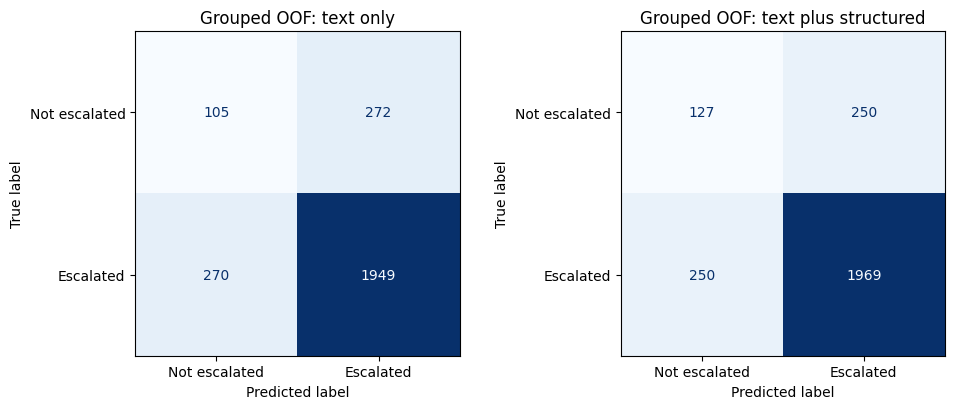

In [17]:
pooled_rows=[]
for variant in VARIANTS:
    d=oof[oof.model==variant].copy()
    assert len(d)==len(all_data) and d.ticket_id.is_unique
    truth=d.escalation_label.to_numpy();pred=d.prediction.to_numpy();score=d.risk_score.to_numpy()
    tn,fp,fn,tp=confusion_matrix(truth,pred,labels=[0,1]).ravel()
    pooled_rows.append({'model':variant,'tickets':len(d),'accuracy':accuracy_score(truth,pred),
        'balanced_accuracy':balanced_accuracy_score(truth,pred),'precision':precision_score(truth,pred,zero_division=0),
        'recall':recall_score(truth,pred),'f1':f1_score(truth,pred),'average_precision':average_precision_score(truth,score),
        'roc_auc':roc_auc_score(truth,score),'alert_rate':pred.mean(),'tn':int(tn),'fp':int(fp),'fn':int(fn),'tp':int(tp)})
    pd.DataFrame(confusion_matrix(truth,pred,labels=[0,1]),index=['actual_not_escalated','actual_escalated'],
        columns=['predicted_not_escalated','predicted_escalated']).to_csv(RESULTS/f'grouped_confusion_{variant}.csv')
    (RESULTS/f'grouped_classification_{variant}.json').write_text(json.dumps(classification_report(truth,pred,
        target_names=['not_escalated','escalated'],output_dict=True,zero_division=0),indent=2))
pooled_rows.append({'model':'always_alert','tickets':len(all_y),'accuracy':all_y.mean(),'balanced_accuracy':0.5,
    'precision':all_y.mean(),'recall':1.,'f1':2*all_y.mean()/(1+all_y.mean()),'average_precision':all_y.mean(),
    'roc_auc':0.5,'alert_rate':1.,'tn':0,'fp':int((all_y==0).sum()),'fn':0,'tp':int(all_y.sum())})
pooled=pd.DataFrame(pooled_rows)
pooled.to_csv(RESULTS/'grouped_pooled_metrics.csv',index=False)
display(pooled.round(4))
metric_cols=['precision','recall','f1','average_precision','roc_auc','alert_rate']
fold_variability=fold_metrics.groupby('model')[metric_cols].agg(['mean','std','min','max'])
fold_variability.to_csv(RESULTS/'grouped_fold_variability.csv')
display(fold_variability.round(4))
fig,axes=plt.subplots(1,2,figsize=(10,4.2))
for ax,variant in zip(axes,VARIANTS):
    d=oof[oof.model==variant]
    ConfusionMatrixDisplay.from_predictions(d.escalation_label,d.prediction,
        display_labels=['Not escalated','Escalated'],ax=ax,cmap='Blues',colorbar=False)
    ax.set_title('Grouped OOF: '+variant.replace('_',' '))
fig.tight_layout();fig.savefig(RESULTS/'grouped_confusion_comparison.png',dpi=160);plt.show()
(RESULTS/'grouped_run_manifest.json').write_text(json.dumps({'outer_folds':5,'inner_folds':3,'seed':SEED,
 'grouping':['exact model_text','event_group_id','transitive connected components'],'n_tickets':len(all_data),
 'n_groups':len(group_sizes),'largest_group':int(group_sizes.max()),'C_grid':C_GRID,'min_inner_recall':MIN_RECALL,
 'initial_fields_assumed':True,'dates_mixed':True,'exploratory_reused_data':True,
 'selection':'inner OOF AP then minimum inner OOF FP subject to recall >= 0.90'},indent=2))
print('Verified: zero text/event-group overlap across outer folds; disjoint inner groups; one held-out prediction per ticket per model.')


## Reading grouped results

Pooled confusion counts sum held-out predictions across all five outer folds. Each ticket receives one held-out prediction per model, using a fold-specific threshold. Pooled AP/AUC compare scores from different fitted models; also inspect the mean and spread of per-fold ranking metrics. Standard deviations describe variation across five folds, not independent-sample confidence intervals.

Do not compare pooled counts directly with the earlier 458-ticket test: grouped evaluation covers 2,596 tickets and tests a different generalization question. Compare the two model variants within these same grouped folds. Even with stratification, connected groups can cause different class proportions across folds. No new deployment model is selected or fitted on all data by this evaluation.

# Latest: nested grouped evaluation

Executed five outer StratifiedGroupKFold folds with three inner grouped folds for model and threshold selection. All 2,596 previously eligible tickets are evaluated once out-of-fold per model (2,219 escalated; 377 non-escalated). No previously excluded tickets were restored.

811 connected groups keep together shared cleaned model_text or event_group_id, including transitive links. Largest group: 214 tickets. Outer folds contain 518–522 tickets and 75–76 non-escalations each. Assertions verified no exact-text or event-group overlap across outer train/held-out partitions and disjoint inner groups.

Within each outer training fold, C is selected from [0.01,0.1,1,10,100] by inner out-of-fold average precision. Threshold minimizes inner out-of-fold false positives subject to recall >=90%; ties favor recall then threshold. Each fitted one-hot encoder sees only its current training fold. Frozen pretrained text embeddings are reused. Outer labels are used only for evaluation. All classifier fits converged.

## Pooled held-out predictions
| Metric | Text only | Text + category/subcategory/assumed initial priority |
|---|---:|---:|
| False positives | 272 | 250 |
| Missed escalations | 270 | 250 |
| Correctly detected escalations | 1,949 | 1,969 |
| Correctly rejected non-escalations | 105 | 127 |
| Precision | 87.75% | 88.73% |
| Recall | 87.83% | 88.73% |
| F1 | 87.79% | 88.73% |
| Accuracy | 79.12% | 80.74% |
| Balanced accuracy | 57.84% | 61.21% |
| Average precision | 92.53% | 94.96% |
| ROC AUC | 0.7055 | 0.7711 |
| Alert rate | 85.55% | 85.48% |

Structured features produce 22 fewer false positives (8.09% reduction) and 20 fewer missed escalations (7.41% reduction), with almost the same alert rate. Still, 250/377 (66.31%) actual non-escalations are flagged. Always alerting has 377 false positives and no missed escalations, with F1 92.17%; this illustrates why F1 alone is insufficient for the selective-alert objective.

Pooled scores come from five different models/thresholds. Per-fold mean ROC AUC is 0.7085 for text only and 0.7733 for structured inputs. Structured-model recall varies from 80.27% to 93.23% across folds; mean 88.74%, standard deviation 5.24 percentage points. These are fold summaries, not independent confidence intervals. Inner recall >=90% does not guarantee outer recall >=90%.

## Interpretation and limits
This is evidence of a modest exploratory benefit from the added fields under group-held-out evaluation, not proof of production performance. It removes exact-text/event-group overlap; paraphrases may still cross groups. Category/subcategory/priority are assumed correct initial values. Synthetic data, unverified snapshots, retrospective outcomes and repeated examination of this dataset remain limitations.

Dates are mixed by design. This tests unseen groups, not future chronological deployment. Do not compare pooled error counts directly with the previous 458-ticket test; the evaluation set and question differ. No deployment model was selected or overwritten by cross-validation. Previously saved models remain from the earlier experiments.

## New outputs
- results/grouped_pooled_metrics.csv: pooled held-out metrics.
- results/grouped_fold_metrics.csv and grouped_fold_variability.csv: per-fold results and spread.
- results/grouped_oof_predictions.csv: one held-out prediction per ticket per model.
- results/grouped_fold_assignments.csv and grouped_fold_summary.csv: auditable split membership.
- results/grouped_inner_model_selection.csv: training-only model selection.
- results/grouped_confusion_*.csv and grouped_classification_*.json: confusion matrices and classification reports.
- results/grouped_confusion_comparison.png: comparison chart.
- results/grouped_run_manifest.json: grouping and experiment configuration.

---

